In [1]:
import time
import h5py
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt
import sys
from scipy import stats as st
sys.path.append('/sdf/home/j/jwang343/rix101231825_Fe_L_edge/results/Jeff/DataAcceleratorChemRIXS/src/')

from chemrixs.smalldata import SmallData
from chemrixs.utils import *
from pathlib import Path
# %matplotlib widget 

## Create the SmallData Object

In [2]:

# --- config ---
base = '/sdf/data/lcls/ds/rix/'
exp  = 'rix101231825'
run  = 112                  # subsample for speed
fname = f'{base}/{exp}/hdf5/smalldata/{exp}_Run{run:04d}.h5'
fyaml = '../roi_input.yml'   

small_data = SmallData(fname, fyaml)

In [3]:
small_data.open()
dir(small_data)

['_SmallData__file',
 '_SmallData__intgrp',
 '_SmallData__ssgrp',
 '__class__',
 '__del__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__enter__',
 '__eq__',
 '__exit__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 'close',
 'epics',
 'integrating',
 'is_open',
 'open',
 'path',
 'run',
 'runinfo',
 'scantype',
 'singleshot',
 'yaml']

In [4]:
dir(small_data.integrating)

112
setting up properties
dataset prop <functools.cached_property object at 0x7fa02d996b50>
dataset prop <functools.cached_property object at 0x7fa02db8c7d0>
dataset prop <functools.cached_property object at 0x7fa02e48dcd0>
dataset prop <functools.cached_property object at 0x7fa02f0e5190>
dataset prop <functools.cached_property object at 0x7fa47127f2d0>
dataset prop <functools.cached_property object at 0x7fa02f0df290>
dataset prop <functools.cached_property object at 0x7fa02dc18350>
dataset prop <functools.cached_property object at 0x7fa02f11c390>


['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 'axis_svls',
 'countmask',
 'epics',
 'get_scanvar',
 'run',
 'scantype',
 'summing_channels',
 'yaml']

### Mono Encoder Sum

In [8]:
with h5py.File(fname, 'r') as f:
    axis_svls = f['intg/axis_svls']
    print(axis_svls.keys())
    mono_sum = axis_svls['mono_hrencoder_sum_value'][:]  
    mono_eV = axis_svls['scan_var'][:]
    print(mono_sum.shape)

plt.figure()
plt.plot(mono_sum[100:200])
plt.plot(mono_eV[100:200])
plt.show()

<KeysViewHDF5 ['c_piranha_sum_full_area', 'count', 'crix_w8_sum_base_0', 'crix_w8_sum_base_1', 'crix_w8_sum_base_2', 'crix_w8_sum_base_3', 'crix_w8_sum_base_4', 'crix_w8_sum_base_5', 'crix_w8_sum_base_6', 'crix_w8_sum_base_7', 'crix_w8_sum_base_all', 'crix_w8_sum_integral_0', 'crix_w8_sum_integral_1', 'crix_w8_sum_integral_2', 'crix_w8_sum_integral_3', 'crix_w8_sum_integral_4', 'crix_w8_sum_integral_5', 'crix_w8_sum_integral_6', 'crix_w8_sum_integral_7', 'crix_w8_sum_integral_all', 'crix_w8_sum_intensity', 'crix_w8_sum_itrigCount', 'crix_w8_sum_posX', 'crix_w8_sum_posY', 'crix_w8_sum_ptrigCount', 'det_crix_w8_sum_full_area', 'det_crix_w8_sum_wfintegrate', 'det_rix_fim0_sum_full_area', 'det_rix_fim0_sum_wfintegrate', 'det_rix_fim1_sum_full_area', 'det_rix_fim1_sum_wfintegrate', 'droplet_dense_curve_corr_corrected_image', 'droplet_dense_curve_corr_pj_ax_1_data', 'droplet_nDroplets', 'droplet_nDroplets_all', 'fzp_piranha_sum_full_area', 'lightStatus_sum_laser', 'lightStatus_sum_xray', 'mo

KeyError: "Unable to synchronously open object (object 'scan_var' doesn't exist)"

In [12]:
with h5py.File(fname, 'r') as f:
    axis_svls = f['Sums']
    print(axis_svls.keys())

<KeysViewHDF5 ['c_atmopal_calib', 'c_piranha_calib', 'det_crix_w8_calib', 'det_rix_fim0_calib', 'det_rix_fim1_calib', 'fzp_piranha_calib']>


335


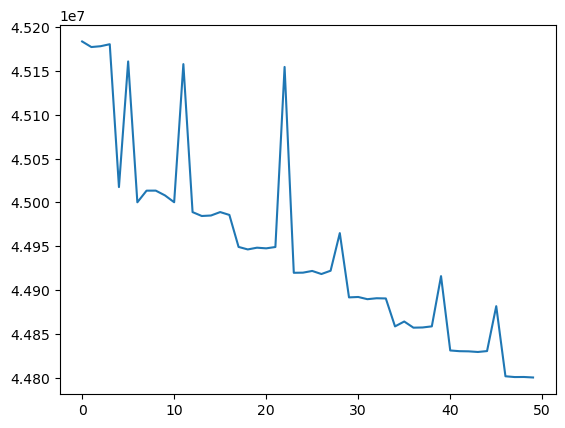

In [7]:
with h5py.File(fname, 'r') as f:
    g = f['intg/axis_svls']
    count   = g['count'][:].squeeze()
    monoenc = g['mono_hrencoder_sum_value'][:].squeeze()
    fim0_wf = g['det_rix_fim0_sum_full_area'][:]
    fim1_wf = g['det_rix_fim1_sum_full_area'][:]


# ---- count mask: keep frames with the expected number of shots ----
mode_c = st.mode(count, keepdims=False)[0]
print(mode_c)
cmask  = (count > mode_c-2) & (count < mode_c+2)
plt.figure()
x = list(range(len(monoenc[0:50])))
plt.plot(x, monoenc[0:50])
plt.show()